# Owner communities

Who owns what, quarter by quarter: every organization in the provider graph placed in one community with its owner, the owner's facilities' legal entities, and the physician groups it employs. `healthcare-ledger owner-communities` builds the tables from a graph built with `--ownership --compendium` ([METHODOLOGY.md](../../docs/METHODOLOGY.md) section 8f). This notebook checks them.

The method is record linkage (Fellegi and Sunter 1969) feeding correlation clustering (Leiden on the Constant Potts Model; Traag, Waltman and van Eck 2019), carried over time by evolutionary clustering (Chakrabarti, Kumar and Tomkins 2006):

* **Hard links** are taken as given. An organization in a CMS All Owners firm (2022 on) is tied to its firm; a firm, or a facility outside any firm, joins the AHRQ Compendium system holding most of its listed facilities; a Compendium physician group joins its system unless it belongs to a staffing company.
* **Soft links** come from NPPES: the authorized official, the mailing address, the practice phone, and a subpart's parent organization. Each shared key gets a probability of common ownership, calibrated once on the pairs whose owner is known on 30 December 2022.
* **Clustering** keeps a community when its pairs are, on the whole, more likely than not to share an owner. Each quarter starts from the last; a pair together last quarter needs p > 0.4 to stay, a new pair p > 0.5 to join.

| Check | Result |
|---|---|
| Held out, NPPES evidence alone: All Owners firms | pair precision 0.69, recall 0.52 |
| Held out, NPPES evidence alone: Compendium system groups | precision 0.82, recall 0.04 (hard links supply the rest) |
| Hand audit, 123 labelled pairs sharing a key | 85 of 98 same-owner pairs together; 7 of 25 different-owner pairs merged |
| Compendium groups in a community with a hospital of their system | 15% of groups, 61% of their physicians |
| Organizations changing community per quarter, no input change | 0.2 to 0.8%, mean 0.4% |
| Moves that return to the community left (A → B → A), 2016-2026 | 4,920 of 104,701 |
| Physicians in groups in a community of two or more | 57% (2016) to 69% (2026) |

The cell below loads the graph's tables. Set `LEDGER_GRAPH` to the graph directory and `LEDGER_WAREHOUSE` to the warehouse (the held-out cells rebuild one quarter's evidence from it).

In [1]:
import csv, json, os, time, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
import duckdb, pandas as pd, numpy as np
import matplotlib.pyplot as plt
from healthcare_ledger.derived import owner_communities as oc

pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 60)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False, "axes.spines.right": False})

GRAPH = Path(os.environ.get("LEDGER_GRAPH", "../../graph")).resolve()
WAREHOUSE = Path(os.environ.get("LEDGER_WAREHOUSE", "../../data/warehouse")).resolve()
m = json.load(open(GRAPH / "manifest.json"))["owner_communities"]
print("owner communities built", m["generated_at"], "|", m["quarters"], "quarters | calibrated on", m["anchor"],
      "| gamma", m["gamma"], "history", m["history"], "| holes filled", m["holes_filled"])
con = duckdb.connect()
for t in ("owner_community_member", "owner_community", "firm_member", "system_link", "hospital_link", "group_size", "organization"):
    con.execute(f"CREATE VIEW {t} AS SELECT * FROM '{GRAPH / t}.parquet'")
ASOF = lambda d, a="": f"{a}effective_date <= DATE '{d}' AND ({a}end_date IS NULL OR {a}end_date > DATE '{d}')"
stats = pd.read_csv(GRAPH / "owner_communities.csv")
calib = pd.read_csv(GRAPH / "owner_link_calibration.csv")
ANCHOR = m["anchor"]

owner communities built 2026-10-31T01:21:54 | 43 quarters | calibrated on 2022-12-30 | gamma 0.5 history 0.1 | holes filled {'firm_member': 5522, 'hospital_link': 292, 'post_acute_link': 1538}


## 1. The calibration

Each cell is a key kind (`ao` the authorized official, `mail`, `phone`, `parent`) by the number of organizations sharing the key, its cohesion and whether the pair shares a name word. The value is the share of known pairs with one owner. A key whose organizations each name their own official is a vendor's (*scattered*); one whose organizations name one official is a family's (*cohesive*). Big cohesive keys with no shared name are where vendors hide, and the calibration prices them low; a shared rare name lifts every cell.

In [2]:
# the calibration: p(same owner) by key kind and cell, among pairs of organizations whose owner is known on the anchor quarter
c = calib.assign(size=calib.cell.str.split("/").str[0], coh=calib.cell.str.split("/").str[1], name=calib.cell.str.split("/").str[2])
print(len(c), "cells,", int(c.pairs.sum()), "known pairs")
for kind in ("ao", "mail", "phone", "parent"):
    t = c[c.kind == kind].pivot_table(index=["size", "coh"], columns="name", values="p").round(2)
    print(f"\n{kind}"); print(t.reindex(columns=["rare name", "name", "common word", "no shared name"]).to_string())

152 cells, 339857 known pairs

ao
name              rare name  name  common word  no shared name
size   coh                                                    
101+   cohesive        0.27  0.54         0.34            0.19
       scattered       1.00  0.99         0.93            0.86
2      cohesive        0.38  0.33          NaN            0.33
       scattered       0.50  0.43         0.32            0.28
21-100 cohesive        0.56  0.75         0.52            0.49
       mixed           0.62  0.71         0.63            0.61
       scattered       0.95  0.63         0.38            0.57
3-5    cohesive        0.48  0.44         0.50            0.33
       mixed           0.63  0.39         0.34            0.25
       scattered       0.54  0.56         0.27            0.26
6-20   cohesive        0.65  0.43         0.44            0.32
       mixed           0.75  0.52         0.27            0.38
       scattered       0.71  0.64         0.47            0.35

mail
name           

## 2. Held out: NPPES evidence alone

Calibrate on half the known owners, drop every hard link, cluster the anchor quarter on NPPES evidence only, and score the other half's pairs. Firms come back with most of their pairs right and half of them found. Compendium system groups come back precise but almost never together: a system's employed groups rarely share an official, address or phone with each other, which is why the Compendium is a hard link.

In [3]:
# held out: calibrate on half the known owners, cluster on NPPES evidence alone (no hard links), score the other half
b = oc.OwnerCommunityBuilder(GRAPH, WAREHOUSE, memory_limit="24GB")
v = b.con
t0 = time.time()
oc.quarter_inputs(v, ANCHOR, b.ahrq_year(ANCHOR)); oc.evidence(v); oc.calibrate(v, half=0)
v.execute("CREATE OR REPLACE TEMP TABLE oc_truth_all AS SELECT 'firm' AS src, pac_id, firm_id AS lab FROM oc_firm "
          "UNION ALL SELECT 'system', pac_id, sys FROM oc_sys_group WHERE pac_id NOT IN (SELECT pac_id FROM oc_firm)")
hard = {t: v.execute(f"SELECT * FROM {t}").df() for t in ("oc_firm", "oc_firm_sys", "oc_fac_sys", "oc_sys_group")}
for t in hard:
    v.execute(f"DELETE FROM {t}")
oc.units(v); oc.cluster(v)
v.execute("CREATE OR REPLACE TEMP TABLE soft AS SELECT * FROM comp")

def pair_scores(src):
    d = v.execute(f"""SELECT t.lab, s.comp FROM oc_truth_all t JOIN soft s ON s.node = t.pac_id
                      WHERE t.src = '{src}' AND hash(t.lab) % 2 = 1""").df()
    pairs = lambda s: (s * (s - 1) / 2).sum()
    tp = pairs(d.groupby(["lab", "comp"]).size())
    return {"organizations": len(d), "precision": round(tp / pairs(d.groupby("comp").size()), 3),
            "recall": round(tp / pairs(d.groupby("lab").size()), 3)}

print(f"({time.time() - t0:.0f}s)")
pd.DataFrame({"All Owners firms (held-out half)": pair_scores("firm"), "AHRQ system groups (held-out half)": pair_scores("system")}).T

(268s)


,organizations,precision,recall
All Owners firms (held-out half),11730.0,0.687,0.517
AHRQ system groups (held-out half),2597.0,0.821,0.037


## 3. Hand audit

250 random pairs of organizations sharing a key on the anchor quarter, 50 per key kind and 50 among staffing families, labelled from names, websites and state filings ([`data/owner_audit_pairs.csv`](data/owner_audit_pairs.csv)). Half could not be called and are left out. Hard links add two same-owner pairs and two different-owner merges over NPPES evidence alone.

In [4]:
# the audit: 250 pairs of organizations sharing a key, drawn on the anchor quarter and labelled by hand from names,
# websites and state filings; 'unclear' pairs are left out
audit = pd.read_csv("data/owner_audit_pairs.csv", dtype={"x": str, "y": str})
mem = con.execute(f"SELECT pac_id, community_id FROM owner_community_member WHERE {ASOF(ANCHOR)}").df().set_index("pac_id").community_id
soft = v.execute("SELECT node, comp FROM soft").df().set_index("node").comp
def audit_scores(memb):
    a = audit[audit.label.isin(["same", "different"]) & audit.x.isin(memb.index) & audit.y.isin(memb.index)].copy()
    a["together"] = memb[a.x].values == memb[a.y].values
    return a.groupby("label").together.agg(["sum", "count"]).rename(columns={"sum": "together", "count": "pairs"})
print(audit.label.value_counts().to_dict())
pd.concat({"NPPES evidence only": audit_scores(soft), "owner communities": audit_scores(mem)}, axis=1)

{'unclear': 127, 'same': 98, 'different': 25}


NPPES evidence only       owner communities      
                     together pairs          together pairs
label                                                      
different                   5    25                 7    25
same                       83    98                85    98

## 4. The hard links at work

A Compendium physician group should land in the community of its system's hospitals. On the anchor quarter 15% of the groups do, but they hold 61% of the groups' physicians: the large employed groups are placed. A group misses when the graph links none of its system's hospitals to an enrollment in its community, or when it belongs to a staffing company (next cell).

In [5]:
# the hard links at work on the anchor quarter: AHRQ system groups whose community holds a hospital of their system
y = b.ahrq_year(ANCHOR)
coloc = con.execute(f"""
    WITH mem AS (SELECT pac_id, community_id FROM owner_community_member WHERE {ASOF(ANCHOR)}),
    sg AS (SELECT node_id AS pac_id, min(health_sys_id) AS sys FROM system_link WHERE year = {y} AND node_type = 'organization' GROUP BY 1),
    sh AS (SELECT node_id AS ccn, min(health_sys_id) AS sys FROM system_link WHERE year = {y} AND node_type = 'hospital' GROUP BY 1),
    hosp_org AS (SELECT organization_pac_id AS pac_id, ccn FROM hospital_link WHERE {ASOF(ANCHOR)}
                 UNION SELECT p.node_id, c.node_id FROM firm_member p JOIN firm_member c USING (firm_id)
                 WHERE p.node_type = 'pac' AND c.node_type = 'ccn' AND {ASOF(ANCHOR, 'p.')} AND {ASOF(ANCHOR, 'c.')}),
    comm_sys AS (SELECT DISTINCT mem.community_id, sh.sys FROM hosp_org JOIN sh USING (ccn) JOIN mem USING (pac_id)),
    ph AS (SELECT organization_pac_id AS pac_id, physicians FROM group_size
           WHERE as_of_date = (SELECT max(as_of_date) FROM group_size WHERE as_of_date <= DATE '{ANCHOR}'))
    SELECT count(*) AS groups, round(100 * avg((cs.sys IS NOT NULL)::INT), 1) AS pct_groups,
           round(100 * sum(coalesce(ph.physicians, 0)) FILTER (cs.sys IS NOT NULL) / sum(coalesce(ph.physicians, 0)), 1) AS pct_physicians
    FROM sg JOIN mem USING (pac_id) LEFT JOIN ph USING (pac_id) LEFT JOIN comm_sys cs ON cs.community_id = mem.community_id AND cs.sys = sg.sys
""").df()
coloc

,groups,pct_groups,pct_physicians
0,35245,15.3,61.1


## 5. Staffing families

Hospitalist and emergency staffing companies contract with many systems, and AHRQ places each of their tax ids in the system it staffs. A family key (parent name, cohesive key, or an official signing for organizations at a few addresses) shared by Compendium groups in three or more systems marks the family as a staffing company's; its groups keep their family and are not pulled into the systems. The communities below are named for their largest organization, since they have no system or firm.

In [6]:
# staffing families on the anchor quarter: NPPES families whose groups AHRQ places in three or more systems keep their family
for t, df in hard.items():
    v.register("_h", df); v.execute(f"INSERT INTO {t} SELECT * FROM _h"); v.unregister("_h")
oc.units(v)
con.register("staffing", v.execute("SELECT pac_id, sys FROM oc_staffing JOIN oc_sys_group USING (pac_id)").df())
staff = con.execute(f"""SELECT m.community_id, count(*) AS groups, count(DISTINCT s.sys) AS systems
    FROM staffing s JOIN owner_community_member m USING (pac_id) WHERE {ASOF(ANCHOR, 'm.')} GROUP BY 1""").df()
names = con.execute(f"SELECT community_id, name, n_organizations, physicians FROM owner_community WHERE {ASOF(ANCHOR)}").df()
print(len(v.execute("SELECT * FROM oc_staffing").df()), "Compendium groups in staffing families on", ANCHOR)
staff.merge(names, on="community_id").sort_values("groups", ascending=False).head(12).reset_index(drop=True)

408 Compendium groups in staffing families on 2022-12-30


,community_id,groups,systems,name,n_organizations,physicians
0,O6901164938,31,15,"THE BORTOLAZZO GROUP, LLC",64,1047.0
1,O0042106478,26,19,"HOSPITALIST MEDICINE PHYSICIANS OF CALIFORNIA, INC",67,1460.3
2,O0143542936,21,6,"INPATIENT SERVICES OF CALIFORNIA, A MEDICAL CORPORATION",44,463.4
3,O0547241598,18,10,"WESTERN VIRGINIA REGIONAL EMERGENCY PHYSICIANS, LLC",51,523.7
4,O3274753207,16,9,QUESTCARE MEDICAL SERVICES PLLC,54,721.9
5,O0042365991,16,8,"NORTHSIDE EMERGENCY ASSOCIATES, P.C.",54,664.1
6,O0345310256,13,9,APOGEE MEDICAL GROUP OF PENNSYLVANIA PC,28,813.9
7,O1456625847,12,10,"HOSPITALIST MEDICINE PHYSICIANS OF TEXAS, PLLC",113,1867.0
8,O0547252223,12,10,SHERIDAN HEALTHCORP INC,47,843.2
9,O0143468447,11,6,BELLE CHASSE PHYSICIAN SERVICES LLC,61,592.1


## 6. Over time

Left: organizations in a community of two or more, by how they are tied in. All Owners firms (black line, September 2022) take over from NPPES keys for facilities; Compendium years are dotted. Right: the share of physicians whose groups sit in a community of two or more.

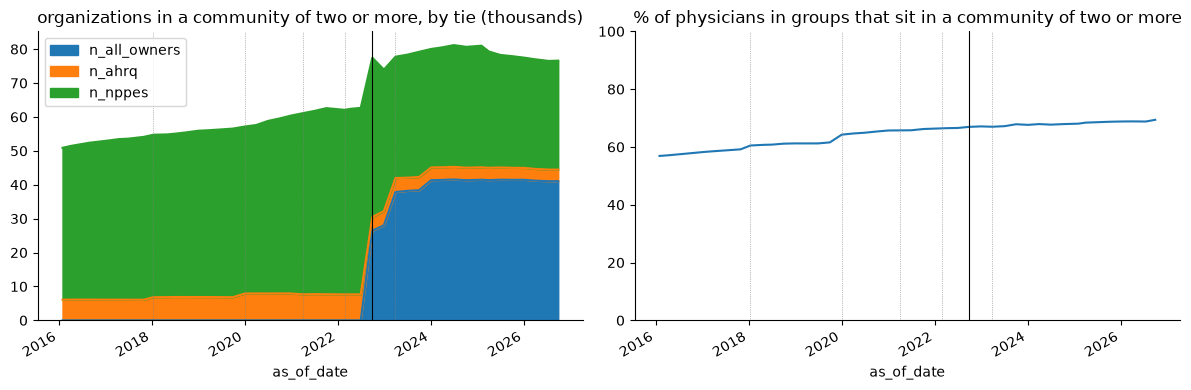

,ahrq_year,all_owners,n_communities_multi,n_organizations_multi,physicians_multi,physicians,n_all_owners,n_ahrq,n_nppes,n_staffing,churn
0,2016,False,13512,50854,362976.9,638015.1,0,6097,44802,219,NaN
1,2016,False,13564,51405,367561.1,643771.8,0,6123,45325,230,0.0039
2,2016,False,13823,52352,377701.7,654686.2,0,6119,46277,235,0.0055
3,2016,False,13970,52977,387023.2,664070.2,0,6105,46913,239,0.0056
4,2016,False,14139,53427,389973.1,665722.9,0,6095,47373,239,0.0038
5,2016,False,14181,53563,391986.8,666657.5,0,6095,47508,237,0.0019
6,2016,False,14269,54073,402480.1,680163.0,0,6087,48028,241,0.0039
7,2018,False,14307,54711,414391.6,685003.9,0,6821,47934,259,0.0147
8,2018,False,14379,54802,416325.1,685477.1,0,6851,47995,261,0.0039
9,2018,False,14380,55018,417389.5,686468.2,0,6894,48168,224,0.0027


In [7]:
b.close()
# over time: communities, the basis organizations are tied in by, and churn
s = stats.set_index(pd.to_datetime(stats.as_of_date))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
(s[["n_all_owners", "n_ahrq", "n_nppes"]] / 1000).plot.area(ax=ax[0], title="organizations in a community of two or more, by tie (thousands)")
(100 * s.physicians_multi / s.physicians).plot(ax=ax[1], title="% of physicians in groups that sit in a community of two or more", ylim=(0, 100))
for a in ax:
    for d in s.index[s.ahrq_year.diff().fillna(0) != 0]:
        a.axvline(d, color="grey", lw=0.5, ls=":")
    a.axvline(pd.Timestamp(m["all_owners_from"]), color="black", lw=0.8)
plt.tight_layout(); plt.show()
s[["ahrq_year", "all_owners", "n_communities_multi", "n_organizations_multi", "physicians_multi", "physicians",
   "n_all_owners", "n_ahrq", "n_nppes", "n_staffing", "churn"]].reset_index(drop=True)

Churn is the share of organizations whose community changes. It roughly triples when an input changes: a new Compendium year (2018, 2020, 2021, 2022, 2023; the 2023 switch coincides with the Enrollments files adding home health agencies) or the start of All Owners firms. Otherwise it stays under 0.8%.

In [8]:
# churn by what changed in the inputs
s["input change"] = np.where(s.ahrq_year.diff().fillna(0) != 0, "AHRQ year",
                     np.where(s.index == pd.Timestamp(m["all_owners_from"]), "All Owners start",
                     np.where(s.index == pd.Timestamp("2023-03-31"), "Enrollments add home health", "none")))
s.iloc[1:].groupby("input change").churn.describe()[["count", "mean", "min", "max"]].round(4)

,count,mean,min,max
input change,,,,
AHRQ year,5.0,0.0128,0.0091,0.0166
All Owners start,1.0,0.0106,0.0106,0.0106
none,36.0,0.0042,0.0019,0.0078


## 7. Flicker

An organization that leaves its community and comes back to it is the stability failure that matters for panels. Before holes were filled and last quarter's pairs given the history bonus, 8,245 moves of 120,000 were returns; now 4,920 of 104,701 are. The excursions that remain run a median of three months to a year and a half, depending on the quarter of return.

In [9]:
# flicker: an organization that leaves its community and comes back to it (A -> B -> A), over the whole panel
con.execute("""CREATE OR REPLACE TEMP TABLE runs AS
    WITH s AS (SELECT *, lag(community_id) OVER (PARTITION BY pac_id ORDER BY effective_date) AS prev FROM owner_community_member),
    g AS (SELECT *, sum((prev IS DISTINCT FROM community_id)::INT) OVER (PARTITION BY pac_id ORDER BY effective_date) AS run FROM s)
    SELECT pac_id, run, any_value(community_id) AS cid, min(effective_date) AS a FROM g GROUP BY 1, 2""")
con.execute("CREATE OR REPLACE TEMP TABLE runs2 AS SELECT *, lag(cid) OVER w AS c1, lag(cid, 2) OVER w AS c2 FROM runs WINDOW w AS (PARTITION BY pac_id ORDER BY run)")
con.execute("""SELECT count(DISTINCT pac_id) AS organizations, count(*) FILTER (c1 IS NOT NULL) AS moves,
               count(*) FILTER (c2 = cid) AS returns, count(DISTINCT pac_id) FILTER (c2 = cid) AS organizations_returning FROM runs2""").df()

,organizations,moves,returns,organizations_returning
0,523237,104701,4920,4454


## 8. The largest communities

On the last quarter, by physicians: the integrated systems, each named for its Compendium system, with the organizations tied in by firm, Compendium and NPPES keys.

In [10]:
# the largest communities on the last quarter, by physicians and by facilities
last = stats.as_of_date.iloc[-1]
oc_last = con.execute(f"SELECT * EXCLUDE (effective_date, end_date) FROM owner_community WHERE {ASOF(last)}").df()
basis = con.execute(f"""SELECT community_id, count(*) FILTER (basis = 'all_owners') AS all_owners, count(*) FILTER (basis = 'ahrq') AS ahrq,
    count(*) FILTER (basis = 'nppes') AS nppes FROM owner_community_member WHERE {ASOF(last)} GROUP BY 1""").df()
oc_last = oc_last.merge(basis, on="community_id")
print(last)
oc_last.sort_values("physicians", ascending=False).head(15).reset_index(drop=True)

2026-09-29


,community_id,name,n_organizations,n_hospitals,n_post_acute,physicians,all_owners,ahrq,nppes
0,O1850367285,Kaiser Permanente,22,40,25,24658.4,14,8,0
1,O0648208504,Advocate Health,96,48,22,9512.6,65,31,0
2,O1355248584,University of California Health,60,3,0,8795.4,5,55,0
3,O1355361742,Mass General Brigham,51,13,2,7844.2,24,27,0
4,O0143138636,Trinity Health,226,83,51,7666.1,141,85,0
5,O0143117556,Ascension Health,237,79,66,7426.4,168,69,0
6,O0143271395,The University of Texas System,13,4,0,7110.0,5,8,0
7,O0042123598,CommonSpirit Health,189,118,59,7098.3,132,57,0
8,O0042124919,Mayo Clinic Health System,15,17,4,6945.9,14,1,0
9,O0941192116,Northwell Health,91,20,7,6639.2,38,53,0


By facilities: the post-acute chains, named for their All Owners firm, with few physicians.

In [11]:
oc_last.assign(facilities=oc_last.n_hospitals + oc_last.n_post_acute).sort_values("facilities", ascending=False).head(15).reset_index(drop=True)

,community_id,name,n_organizations,n_hospitals,n_post_acute,physicians,all_owners,ahrq,nppes,facilities
0,O0042466989,UNITEDHEALTH GROUP INCORPORATED,632,2,445,1.2,632,0,0,447
1,O0143227496,THE ENSIGN GROUP INC,272,8,416,42.5,266,0,6,424
2,O0042246563@2023-10-02,"PACS HOLDINGS, LLC",290,0,249,0.0,290,0,0,249
3,O1658435292,"KENTUCKY HOMECARE HOLDINGS, INC.",124,0,218,0.0,124,0,0,218
4,O0042395931,Universal Health Services,233,138,58,951.8,207,18,8,196
5,O0042128480,Sanford Health,83,42,150,2762.6,79,4,0,192
6,O0042121519,HCA Healthcare,485,151,31,4715.9,264,221,0,182
7,O0042123598,CommonSpirit Health,189,118,59,7098.3,132,57,0,177
8,O0042392334,GEN OPERATIONS II LLC,193,0,160,0.0,193,0,0,160
9,O8820983620,ENCOMPASS HEALTH CORPORATION,178,145,0,0.0,178,0,0,145


## 9. One community through time

The largest by physicians, Kaiser Permanente, keeps one id across all 43 quarters.

## Limits and next steps

* Physicians are counted by the groups they bill through. A system's employed physicians in groups the Compendium does not list and that share no NPPES key with the system stay outside it; IRS Form 990 Schedule R would add them (Luo et al. 2024).
* The Compendium stops at 2023 and is carried forward, so systems' groups after 2023 are frozen except through All Owners and NPPES.
* Firm names come from the All Owners files and are sometimes an owner's agent (an accounting or management firm) rather than the owner.
* The calibration is fixed on one quarter; re-fitting it on the 2023 Compendium would test how much it drifts.

In [12]:
# one community through time: the organizations, facilities and physicians of the largest community by physicians on the last quarter
cid = oc_last.sort_values("physicians", ascending=False).community_id.iloc[0]
con.execute(f"SELECT effective_date, end_date, name, n_organizations, n_hospitals, n_post_acute, physicians FROM owner_community WHERE community_id = '{cid}' ORDER BY 1").df()

,effective_date,end_date,name,n_organizations,n_hospitals,n_post_acute,physicians
0,2016-02-01,2016-04-05,Kaiser Permanente,12,38,8,17307.6
1,2016-04-05,2016-08-30,Kaiser Permanente,12,38,8,17470.6
2,2016-08-30,2017-01-19,Kaiser Permanente,12,38,8,17711.1
3,2017-01-19,2017-04-20,Kaiser Permanente,12,38,8,18167.6
4,2017-04-20,2017-07-02,Kaiser Permanente,12,38,7,18323.0
5,2017-07-02,2017-10-30,Kaiser Permanente,12,38,7,18368.9
6,2017-10-30,2018-01-15,Kaiser Permanente,12,38,7,18556.5
7,2018-01-15,2018-05-02,Kaiser Permanente,11,39,8,20996.2
8,2018-05-02,2018-07-03,Kaiser Permanente,11,39,20,20997.6
9,2018-07-03,2018-10-02,Kaiser Permanente,11,39,20,20915.3
